In [1]:
import cobra
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
import os
from scipy import stats
from statsmodels.stats.multitest import  multipletests
import operator
plt.rcParams['figure.figsize'] = [11, 7]



In [2]:
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

acids_set = ['EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e', 'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e', 'EX_lac__D_e']
acids_c = [model.reactions.get_by_id(r).reactants[0].elements['C'] for r in acids_set]
   
    
aminoacids = ['glu__L', 'ala__L', 'arg__L', 'gly', 'gln__L', 'his__L', 'leu__L','lys__L', 'pro__L', 'ser__L', 
             'phe__L', 'asn__L', 'ile__L', 'met__L', 'thr__L', 'trp__L', 'tyr__L', 'val__L', 'cys__L', 'asp__L']
aminoacids_c = [model.metabolites.get_by_id(r+'_c').elements['C'] for r in aminoacids]
aminoacids_n =  [model.metabolites.get_by_id(r+'_c').elements['N'] for r in aminoacids]


Set parameter Username
Set parameter LicenseID to value 2866505
Academic license - for non-commercial use only - expires 2027-09-22


In [3]:
from pathlib import Path
import pandas as pd
from scipy import stats as st

directory = Path('results_new/genome_scale_samples_no_exchange_PEAKS/')
directory = Path('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/')

# Get and sort files by cell ID
files = sorted(
    directory.glob('std_1000samples_cell*.dat'),
    key=lambda f: int(f.stem.split('cell')[-1])
)

means_list = []
stds_list = []
modes_list = []
ids = []

for f in files:
    cell_id = int(f.stem.split('cell')[-1])
    ids.append(cell_id)

    print(f.name)
    sample = pd.read_csv(f, sep='\t')

    means_list.append(sample.mean())
    stds_list.append(sample.std())
    modes_list.append(sample.mode().iloc[0])  # faster than scipy

# Build DataFrames with correct order
means = pd.DataFrame(means_list, index=ids)
stds = pd.DataFrame(stds_list, index=ids)
modes = pd.DataFrame(modes_list, index=ids)

std_1000samples_cell2.dat
std_1000samples_cell3.dat
std_1000samples_cell4.dat
std_1000samples_cell7.dat
std_1000samples_cell9.dat
std_1000samples_cell10.dat
std_1000samples_cell11.dat
std_1000samples_cell12.dat
std_1000samples_cell13.dat
std_1000samples_cell14.dat
std_1000samples_cell15.dat
std_1000samples_cell17.dat
std_1000samples_cell18.dat
std_1000samples_cell19.dat
std_1000samples_cell20.dat
std_1000samples_cell21.dat
std_1000samples_cell22.dat
std_1000samples_cell23.dat
std_1000samples_cell24.dat
std_1000samples_cell25.dat
std_1000samples_cell26.dat
std_1000samples_cell27.dat
std_1000samples_cell29.dat
std_1000samples_cell30.dat
std_1000samples_cell31.dat
std_1000samples_cell32.dat
std_1000samples_cell34.dat
std_1000samples_cell35.dat
std_1000samples_cell36.dat
std_1000samples_cell38.dat
std_1000samples_cell39.dat
std_1000samples_cell41.dat
std_1000samples_cell42.dat
std_1000samples_cell43.dat
std_1000samples_cell45.dat
std_1000samples_cell46.dat
std_1000samples_cell47.dat
std_10

In [ ]:
means.to_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat', sep='\t', index=False)
stds.to_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat', sep='\t', index=False)
modes.to_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_modes.dat', sep='\t', index=False)


In [4]:
means.to_csv('results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat', sep='\t', index=False)
stds.to_csv('results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat', sep='\t', index=False)
modes.to_csv('results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_modes.dat', sep='\t', index=False)


In [3]:
means2 = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat', sep='\t')
stds2 = pd.read_csv('results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat', sep='\t')

In [4]:
means_toy = pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_4ox.dat', sep='\t')

In [5]:
cluster = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat')
cluster

,cluster
0,1
1,1
2,0
3,0
4,0
...,...
515,0
516,0
517,1
518,0


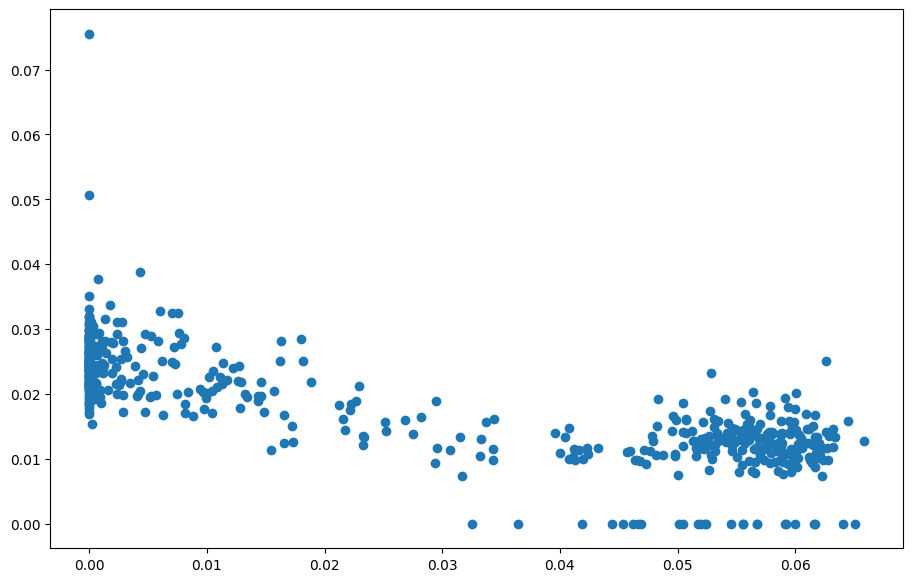

In [6]:
plt.scatter(means2['BIOMASS_Ec_SynMixo'], means2['CYPHYC'])

/home/arianferrero/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


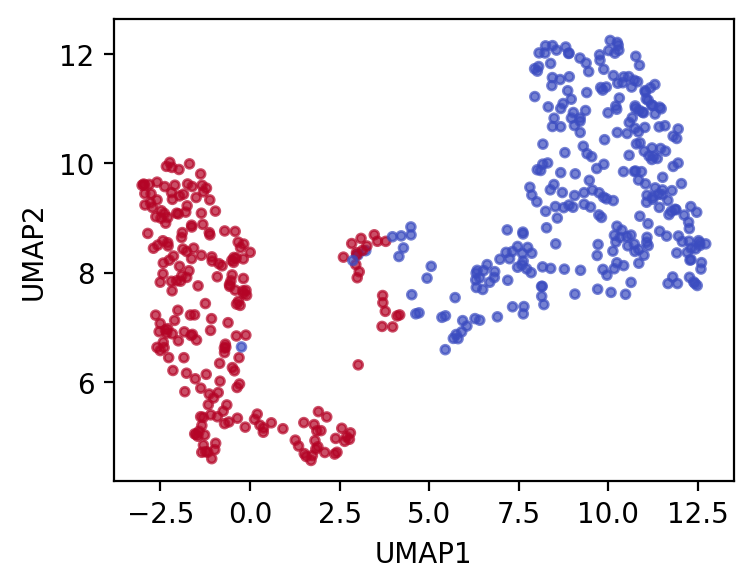

In [22]:
from sklearn.preprocessing import StandardScaler
import umap

cluster = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat')
X = StandardScaler().fit_transform(means2)
#X = StandardScaler().fit_transform(means_toy)

embedding = umap.UMAP(
    n_neighbors=13,
    min_dist=0.3,
    random_state=0
).fit_transform(X)

plt.figure(figsize=(4,3), dpi=200)

plt.scatter(
    embedding[:,0],
    embedding[:,1],
    s=10,
    alpha=0.7, c= [i for i in cluster['cluster']], cmap='coolwarm'
)

#plt.scatter(
#    embedding[:,0],
#    embedding[:,1],
#    s=10,
#    alpha=0.7, c= [1 if i>0 else 0 for i in means_toy['ac']]
#)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.show()

In [6]:
means = pd.read_csv('results_new/genome_scale_samples_no_exchange/std_sampling_exchange_averages.dat', sep='\t')
stds = pd.read_csv('results_new/genome_scale_samples_no_exchange/std_sampling_exchange_stds.dat', sep='\t')

In [6]:
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

acids_set = ['EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e', 'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e', 'EX_lac__D_e']
acids_c = [model.reactions.get_by_id(r).reactants[0].elements['C'] for r in acids_set]
   
    
aminoacids = ['glu__L', 'ala__L', 'arg__L', 'gly', 'gln__L', 'his__L', 'leu__L','lys__L', 'pro__L', 'ser__L', 
             'phe__L', 'asn__L', 'ile__L', 'met__L', 'thr__L', 'trp__L', 'tyr__L', 'val__L', 'cys__L', 'asp__L']
aminoacids_c = [model.metabolites.get_by_id(r+'_c').elements['C'] for r in aminoacids]
aminoacids_n =  [model.metabolites.get_by_id(r+'_c').elements['N'] for r in aminoacids]

means = means2
aminoacid_C_flux = []
total_C_uptake = []
acid_C_flux = []
for cell in means.iterrows():
    fluxes = cell[1]
    summ = np.sum([fluxes['EX_'+aa+'_e']*aminoacids_c[i] for i,aa in enumerate(aminoacids)])
    aminoacid_C_flux.append(summ)
    
    summ_ac = np.sum([fluxes[a]*acids_c[i] for i,a in enumerate(acids_set)])
    acid_C_flux.append(summ_ac)
    
    total_C_uptake.append(fluxes['EX_hco3_e'] + min(0,summ) + min(0,summ_ac))

Set parameter Username
Set parameter LicenseID to value 2866505
Academic license - for non-commercial use only - expires 2027-09-22


/tmp/ipykernel_5545/2322022517.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipykernel_5545/2322022517.py:139: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.savefig('secretion_pattern_previous.png', dpi=200)
/home/arianferrero/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


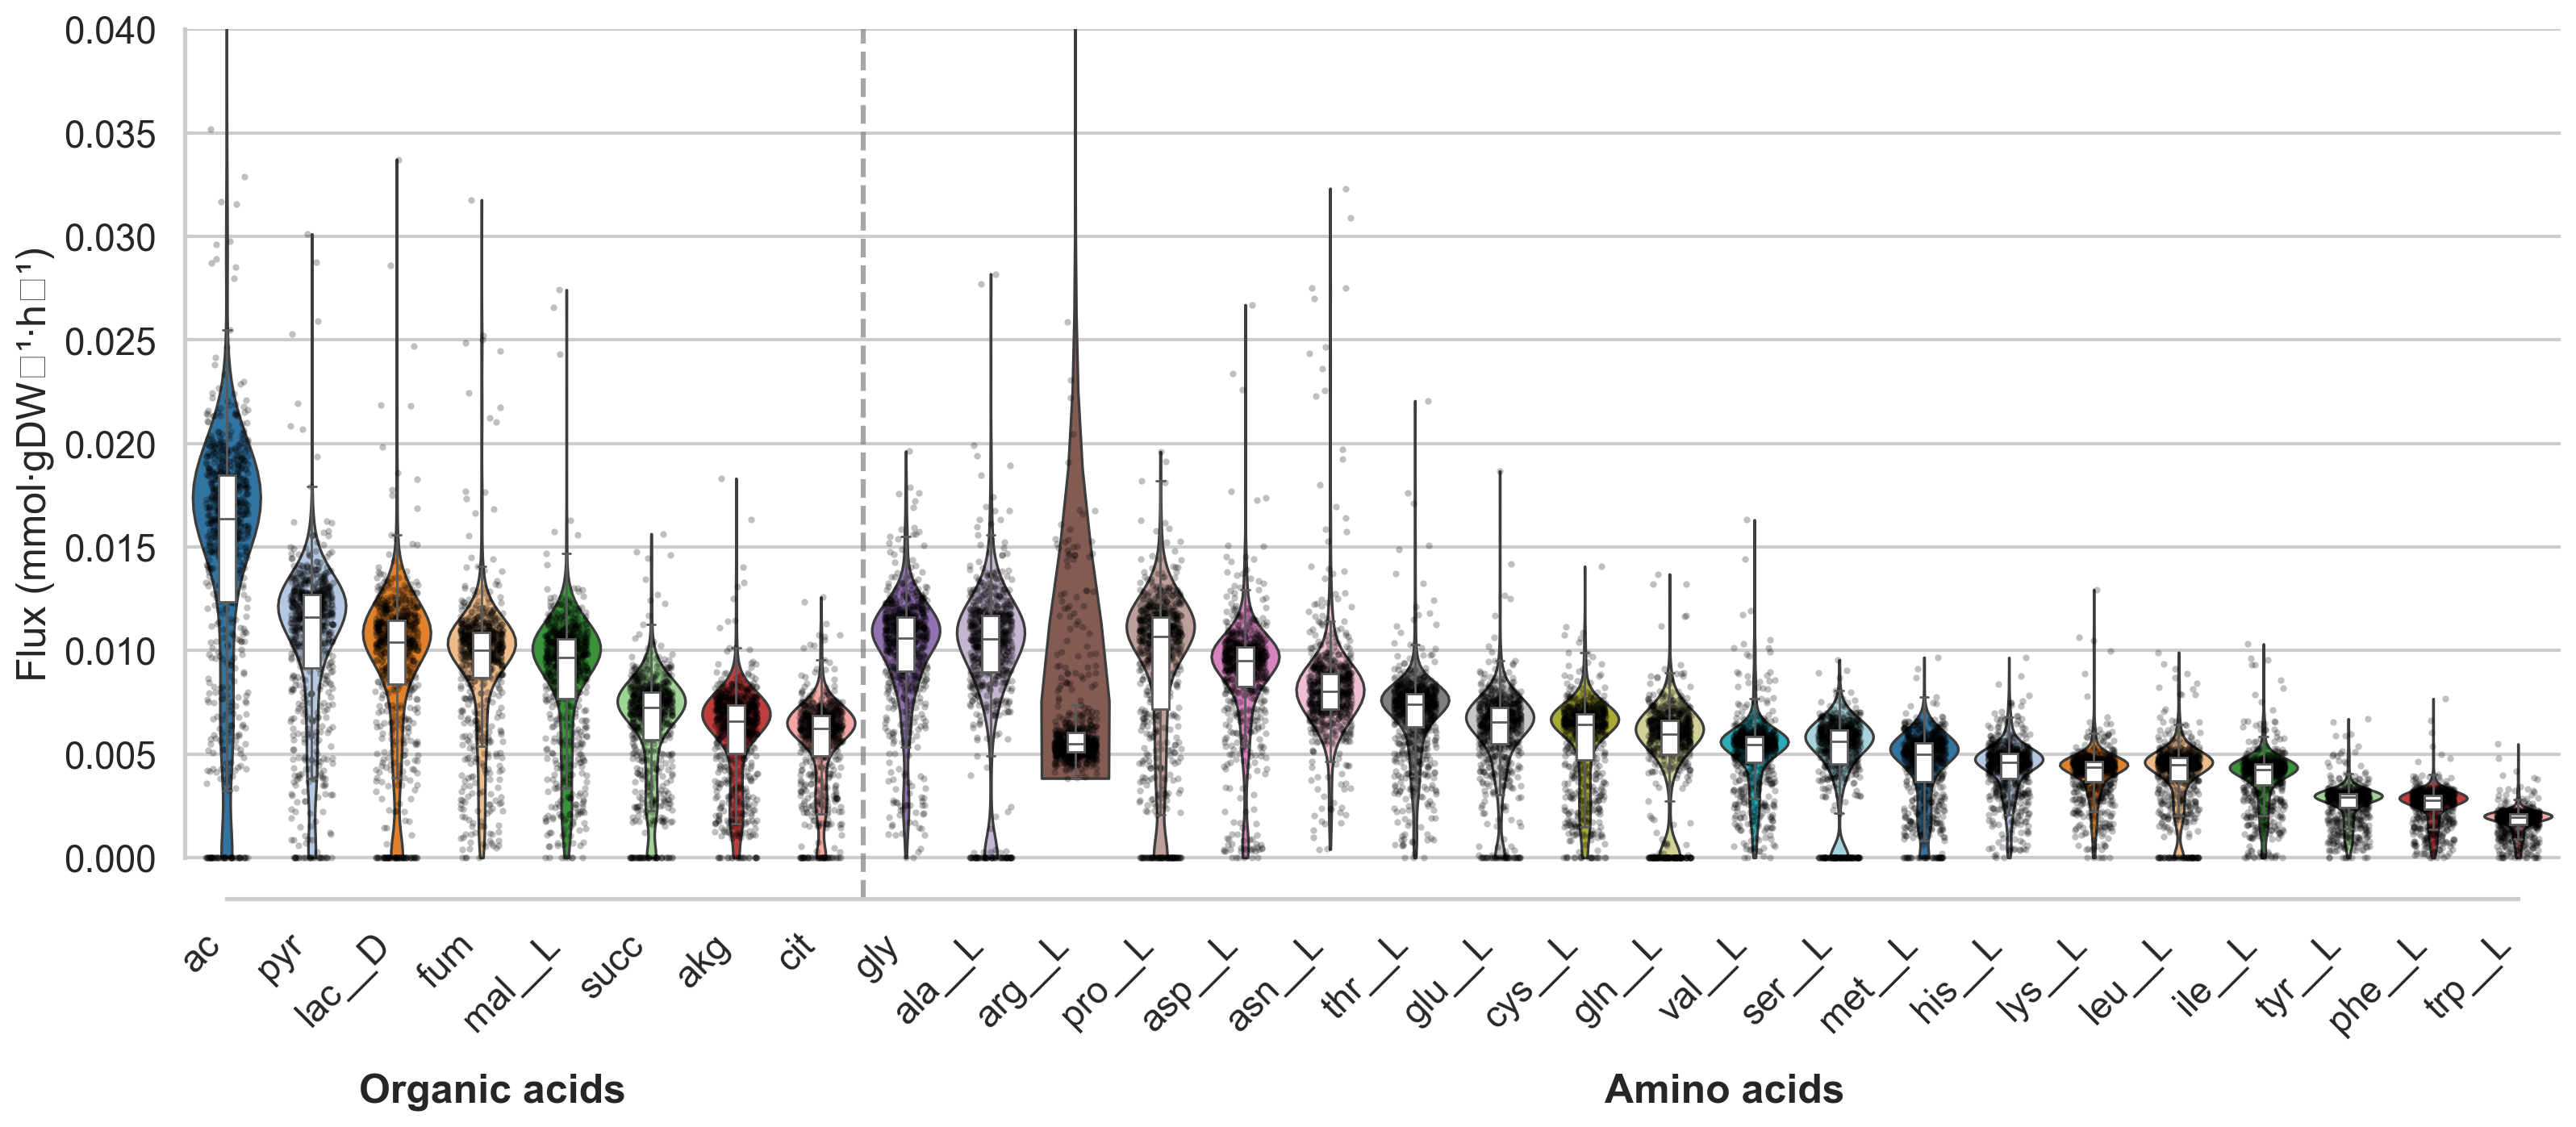

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd


# NO EXCHANGE


means = pd.read_csv('results_new/genome_scale_samples_no_exchange/std_sampling_exchange_averages.dat', sep='\t')
stds = pd.read_csv('results_new/genome_scale_samples_no_exchange/std_sampling_exchange_stds.dat', sep='\t')

#means = pd.read_csv('results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat', sep='\t')
#stds = pd.read_csv('results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat', sep='\t')


# ---- Data prep ----
data = []
labels = []
groups = []

# Acids
for acid in acids_set:
    vals = means[acid]
    lab = acid[3:-2]

    data.extend(vals)
    labels.extend([lab] * len(vals))
    groups.extend(["Acids"] * len(vals))

# Amino acids
for aa in aminoacids:
    vals = means[f'EX_{aa}_e']

    data.extend(vals)
    labels.extend([aa] * len(vals))
    groups.extend(["Amino acids"] * len(vals))

df = pd.DataFrame({
    "value": data,
    "compound": labels,
    "group": groups
})

# ---- ORDER WITHIN GROUPS ONLY ----
acid_order = (
    df[df["group"] == "Acids"]
    .groupby("compound")["value"]
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist()
)

aa_order = (
    df[df["group"] == "Amino acids"]
    .groupby("compound")["value"]
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist()
)

order = acid_order + aa_order

# ---- index split ----
n_acids = len(acid_order)

# ---- Styling ----
sns.set_theme(style="whitegrid", context="talk")
palette = sns.color_palette("tab20", len(order))

# ---- Plot ----
fig, ax = plt.subplots(figsize=(19, 7), dpi=200)

sns.violinplot(
    data=df,
    x="compound",
    y="value",
    order=order,
    palette=palette,
    inner=None,
    cut=0,
    linewidth=1.2,
    ax=ax
)

sns.boxplot(
    data=df,
    x="compound",
    y="value",
    order=order,
    width=0.2,
    boxprops={'facecolor': 'white'},
    showfliers=False,
    ax=ax,
    zorder=10
)

sns.stripplot(
    data=df,
    x="compound",
    y="value",
    order=order,
    color="black",
    size=3,
    alpha=0.25,
    jitter=0.25,
    ax=ax
)

# ---- separator ----
ax.axvline(n_acids - 0.5, color="gray", linestyle="--", alpha=0.7)

# ---- group labels ----
y_text = -0.2

acid_center = (n_acids - 1) / 2
aa_center = n_acids + (len(order) - n_acids - 1) / 2

acid_frac = acid_center / (len(order) - 1)
aa_frac = aa_center / (len(order) - 1)

ax.text(acid_frac, y_text, "Organic acids",
        transform=ax.transAxes,
        ha="center", va="top", fontweight="bold")

ax.text(aa_frac, y_text, "Amino acids",
        transform=ax.transAxes,
        ha="center", va="top", fontweight="bold")

# ---- polish ----
plt.ylim(-0.002, 0.04)
plt.xticks(rotation=45, ha="right")
plt.xlabel("")
plt.ylabel("Flux (mmol·gDW⁻¹·h⁻¹)")
#plt.title("Distribution of Secretion Fluxes")

sns.despine(trim=True)
plt.savefig('secretion_pattern_previous.png', dpi=200)
plt.show()

/tmp/ipykernel_39681/1897671015.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


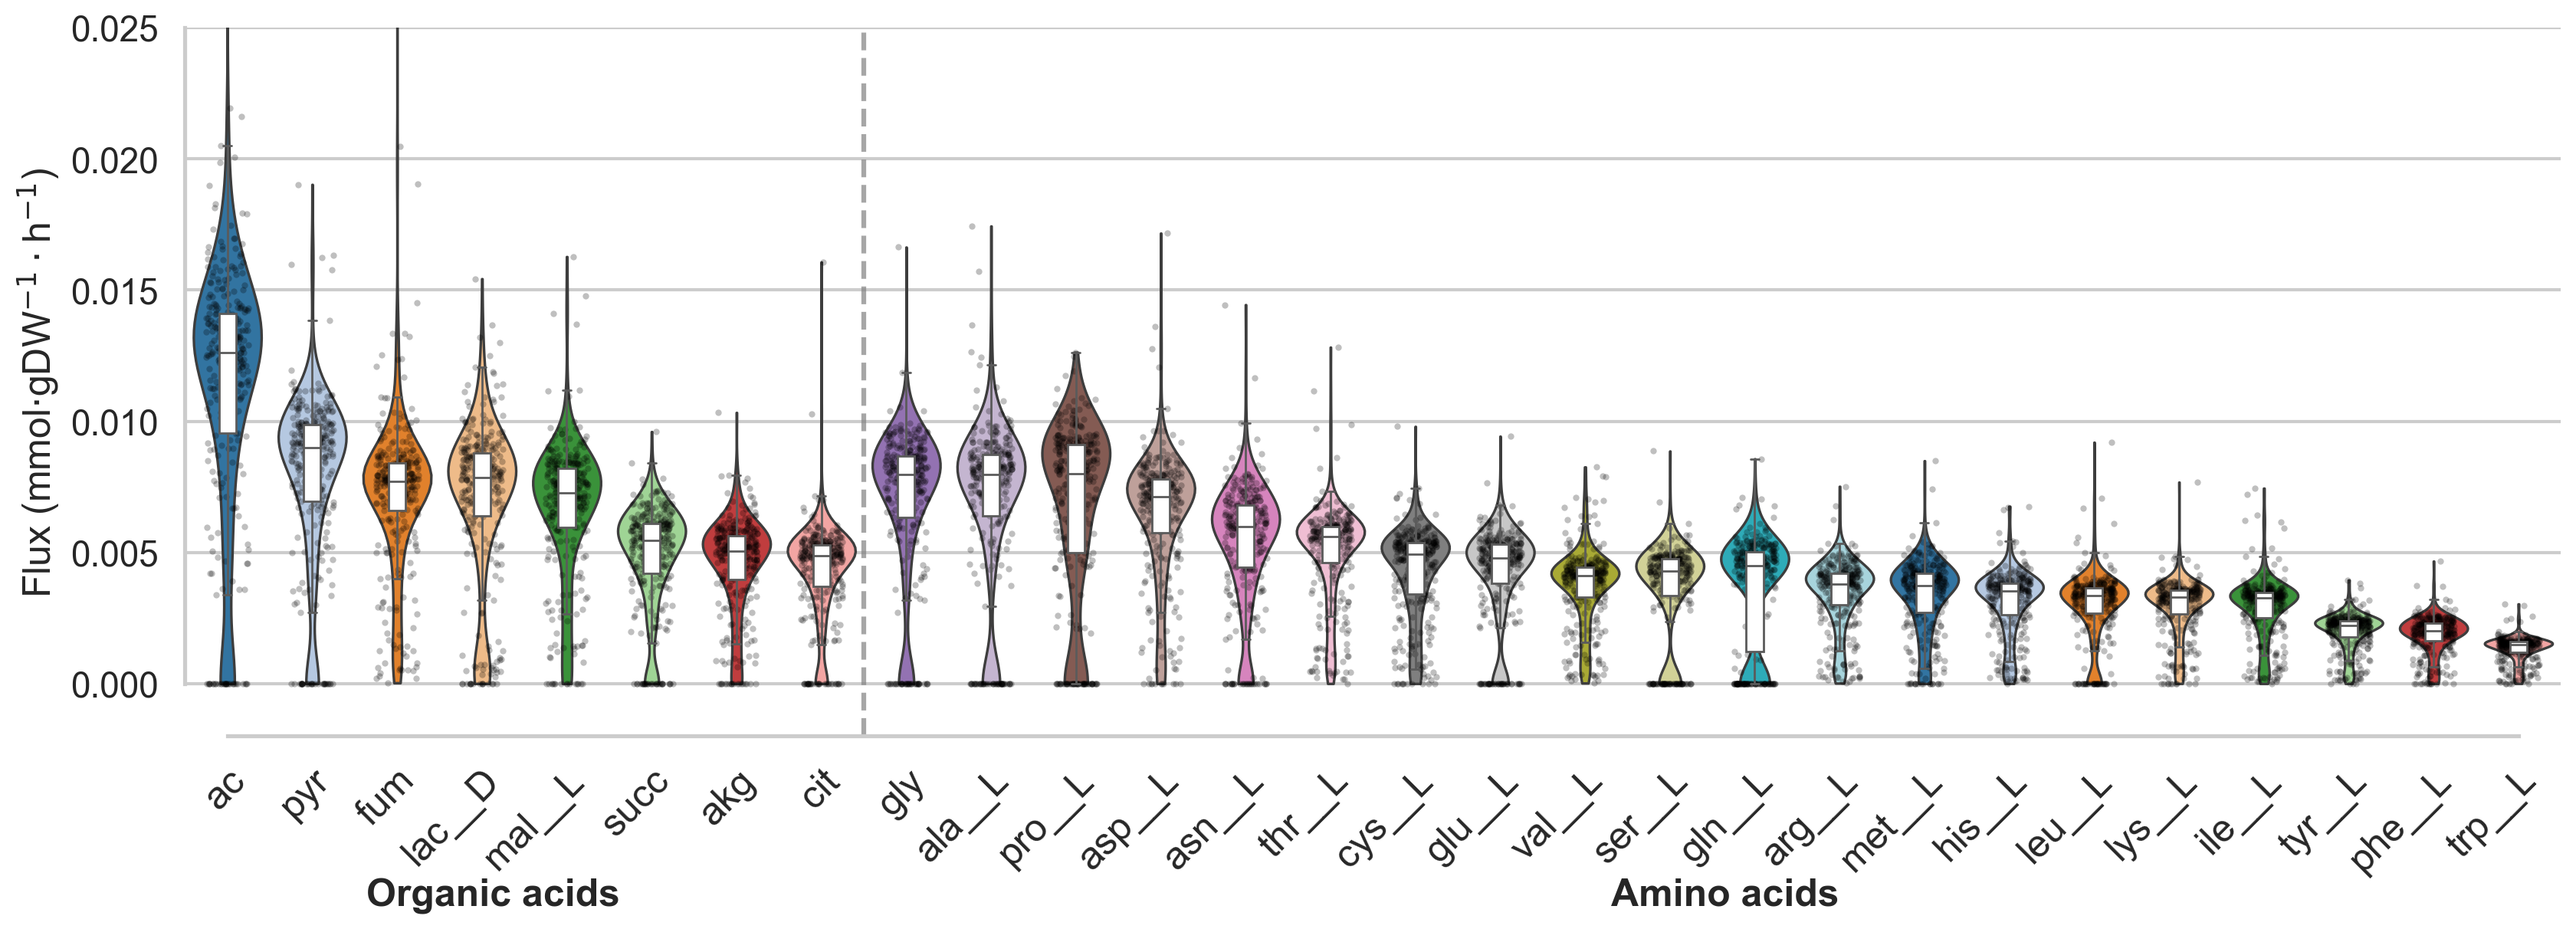

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# NO EXCHANGE
means = pd.read_csv('results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat', sep='\t')
stds = pd.read_csv('results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat', sep='\t')

# ---- Data prep ----
data = []
labels = []
groups = []

# Acids
for acid in acids_set:
    vals = means[acid]
    lab = acid[3:-2]
    data.extend(vals)
    labels.extend([lab] * len(vals))
    groups.extend(["Acids"] * len(vals))

# Amino acids
for aa in aminoacids:
    vals = means[f'EX_{aa}_e']
    data.extend(vals)
    labels.extend([aa] * len(vals))
    groups.extend(["Amino acids"] * len(vals))

df = pd.DataFrame({
    "value": data,
    "compound": labels,
    "group": groups
})

# ---- ORDER WITHIN GROUPS ONLY ----
acid_order = (
    df[df["group"] == "Acids"]
    .groupby("compound")["value"]
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist()
)
aa_order = (
    df[df["group"] == "Amino acids"]
    .groupby("compound")["value"]
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist()
)
order = acid_order + aa_order
n_acids = len(acid_order)

# ---- outlier compound to break out into its own inset ----
OUTLIER = "arg__L"
arg_idx = order.index(OUTLIER)

# ---- Styling ----
sns.set_theme(style="whitegrid", context="talk")
palette = sns.color_palette("tab20", len(order))

# ---- y-limits: main plot clipped so the low-flux compounds are legible,
#      the outlier's own violin/box/strip are re-drawn at full scale in axins ----
MAIN_YLIM = (-0.002, 0.025)
INSET_YLIM = (0.06, 0.2)

# ---- Plot ----
fig, ax = plt.subplots(figsize=(20, 6), dpi=200)

sns.violinplot(
    data=df, x="compound", y="value",
    order=order, palette=palette,
    inner=None, cut=0, linewidth=1.2,
    ax=ax
)
sns.boxplot(
    data=df, x="compound", y="value",
    order=order, width=0.2,
    boxprops={'facecolor': 'white'},
    showfliers=False,
    ax=ax, zorder=10
)
sns.stripplot(
    data=df, x="compound", y="value",
    order=order, color="black",
    size=3, alpha=0.25, jitter=0.25,
    ax=ax
)

ax.set_ylim(*MAIN_YLIM)

# ---- separator ----
ax.axvline(n_acids - 0.5, color="gray", linestyle="--", alpha=0.7)

# ---- group labels ----
y_text = -0.2
acid_center = (n_acids - 1) / 2
aa_center = n_acids + (len(order) - n_acids - 1) / 2
acid_frac = acid_center / (len(order) - 1)
aa_frac = aa_center / (len(order) - 1)
ax.text(acid_frac, y_text, "Organic acids",
        transform=ax.transAxes,
        ha="center", va="top", fontweight="bold")
ax.text(aa_frac, y_text, "Amino acids",
        transform=ax.transAxes,
        ha="center", va="top", fontweight="bold")

## ---- inset showing the outlier (arg_L) at its own scale ----
#axins = inset_axes(
#    ax, width="16%", height="55%",
#    loc="upper right",
#    bbox_to_anchor=(0, 0, 0.98, 0.98),
#    bbox_transform=ax.transAxes,
#    borderpad=0,
#)
#
#arg_vals = df.loc[df["compound"] == OUTLIER, "value"].to_numpy()
#
#vp = axins.violinplot(arg_vals, positions=[arg_idx], showmeans=False, showextrema=False)
#for body in vp["bodies"]:
#    body.set_facecolor(palette[arg_idx])
#    body.set_edgecolor("black")
#    body.set_alpha(0.7)
#
#bp = axins.boxplot(
#    arg_vals, positions=[arg_idx], widths=0.2,
#    patch_artist=True, showfliers=False, zorder=10,
#)
#bp["boxes"][0].set_facecolor("white")
#
#jitter = np.random.uniform(-0.1, 0.1, size=len(arg_vals))
#axins.scatter(
#    np.full(len(arg_vals), arg_idx) + jitter, arg_vals,
#    color="black", s=8, alpha=0.25, linewidths=0, zorder=5,
#)
#
## same x-coordinate system as `ax` (so mark_inset lines up with the column below)
#axins.set_xlim(arg_idx - 0.5, arg_idx + 0.5)
#axins.set_ylim(*INSET_YLIM)
#axins.set_xticks([])
#axins.set_title(f"{OUTLIER}\n(note different y-scale)", fontsize=13)
#axins.set_ylabel("")
#sns.despine(ax=axins)
#
## connector lines from the clipped column in `ax` to the inset box
#mark_inset(ax, axins, loc1=3, loc2=4, fc="none", ec="0.5", lw=0.8, linestyle="--")

# ---- polish ----
ax.set_xlabel("")
# mathtext instead of literal unicode superscripts: the "⁻¹" glyph is
# missing from some fonts and was rendering as a blank box / invisible minus
ax.set_ylabel(r"Flux (mmol$\cdot$gDW$^{-1}\cdot$h$^{-1}$)")

# rotate the x tick labels explicitly on `ax` (not via plt.xticks, which
# would act on whichever axes is "current" -- unreliable once an inset has
# been created) and use rotation_mode="anchor" so the rotated labels pivot
# around their end point instead of their center, which is what actually
# fixes the overlap between adjacent labels
ax.tick_params(axis="x", labelsize=18)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

sns.despine(ax=ax, trim=True)

plt.savefig('secretion_pattern.png', dpi=200, bbox_inches="tight")
plt.show()

/tmp/ipykernel_39681/3129916780.py:130: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_39681/3129916780.py:130: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()
/tmp/ipykernel_39681/3129916780.py:131: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  plt.savefig("barplot_Cflux.png", dpi=200, bbox_inches="tight")
/tmp/ipykernel_39681/3129916780.py:131: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.savefig("barplot_Cflux.png", dpi=200, bbox_inches="tight")
/home/arianferrero/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/home/arianferrero/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  

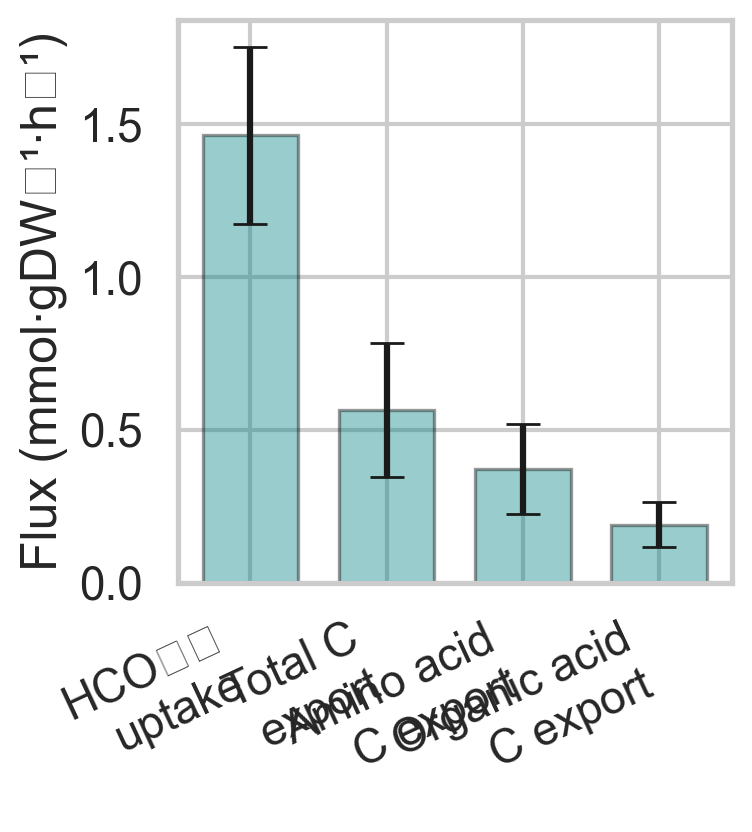

HCO₃⁻
uptake              : 1.4629 ± 0.2897
Total C
export            : 0.5641 ± 0.2190
Amino acid
C export       : 0.3733 ± 0.1475
Organic acid
C export     : 0.1908 ± 0.0727


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cobra
import cobra.io

# -----------------------------
# Load model + data
# -----------------------------
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')

means = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat',
    sep='\t'
)

# -----------------------------
# Define metabolites
# -----------------------------
acids_set = [
    'EX_ac_e', 'EX_pyr_e', 'EX_fum_e', 'EX_succ_e',
    'EX_cit_e', 'EX_akg_e', 'EX_mal__L_e', 'EX_lac__D_e'
]

acids_c = [
    model.reactions.get_by_id(r).reactants[0].elements['C']
    for r in acids_set
]

aminoacids = [
    'glu__L', 'ala__L', 'arg__L', 'gly', 'gln__L', 'his__L',
    'leu__L','lys__L', 'pro__L', 'ser__L',
    'phe__L', 'asn__L', 'ile__L', 'met__L',
    'thr__L', 'trp__L', 'tyr__L', 'val__L',
    'cys__L', 'asp__L'
]

aminoacids_c = [
    model.metabolites.get_by_id(a + '_c').elements['C']
    for a in aminoacids
]

# -----------------------------
# Flux decomposition
# -----------------------------
hco3_flux = []
total_C_release = []
aminoacid_C_flux = []
acid_C_flux = []

for _, row in means.iterrows():
    fluxes = row

    # Amino acid carbon export
    aa_flux = sum(
        fluxes['EX_' + aa + '_e'] * aminoacids_c[i]
        for i, aa in enumerate(aminoacids)
    )

    # Organic acid carbon export
    acid_flux = sum(
        fluxes[r] * acids_c[i]
        for i, r in enumerate(acids_set)
    )

    aminoacid_C_flux.append(aa_flux)
    acid_C_flux.append(acid_flux)

    # Inorganic carbon uptake
    hco3_flux.append(fluxes['RBPC'])#-fluxes['EX_co2_e'])
    
    total_C_release.append(aa_flux+acid_flux)

# -----------------------------
# Statistics
# -----------------------------
def mean_std(x):
    return np.mean(x), np.std(x)

labels = [
    "HCO₃⁻\nuptake",
    "Total C\nexport",
    "Amino acid\nC export",
    "Organic acid\nC export"
]

data = [
    hco3_flux,
    total_C_release,
    aminoacid_C_flux,
    acid_C_flux
]

means_vals = []
std_vals = []

for d in data:
    m, s = mean_std(d)
    means_vals.append(m)
    std_vals.append(s)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(4.1,4.5), dpi=200)

color12 = (0.0, 0.5, 0.5, 0.35)

plt.bar(
    labels,
    means_vals,
    yerr=std_vals,
    capsize=6,
    alpha=0.4,
    width=0.7,
    color=color12,
    edgecolor="black",
    linewidth=1.2
)

plt.ylabel("Flux (mmol·gDW⁻¹·h⁻¹)")
#plt.title("Carbon decomposition (inorganic vs organic)", fontsize=12)

plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig("barplot_Cflux.png", dpi=200, bbox_inches="tight")

plt.show()

# -----------------------------
# Optional: print values
# -----------------------------
for lab, m, s in zip(labels, means_vals, std_vals):
    print(f"{lab:25s} : {m:.4f} ± {s:.4f}")

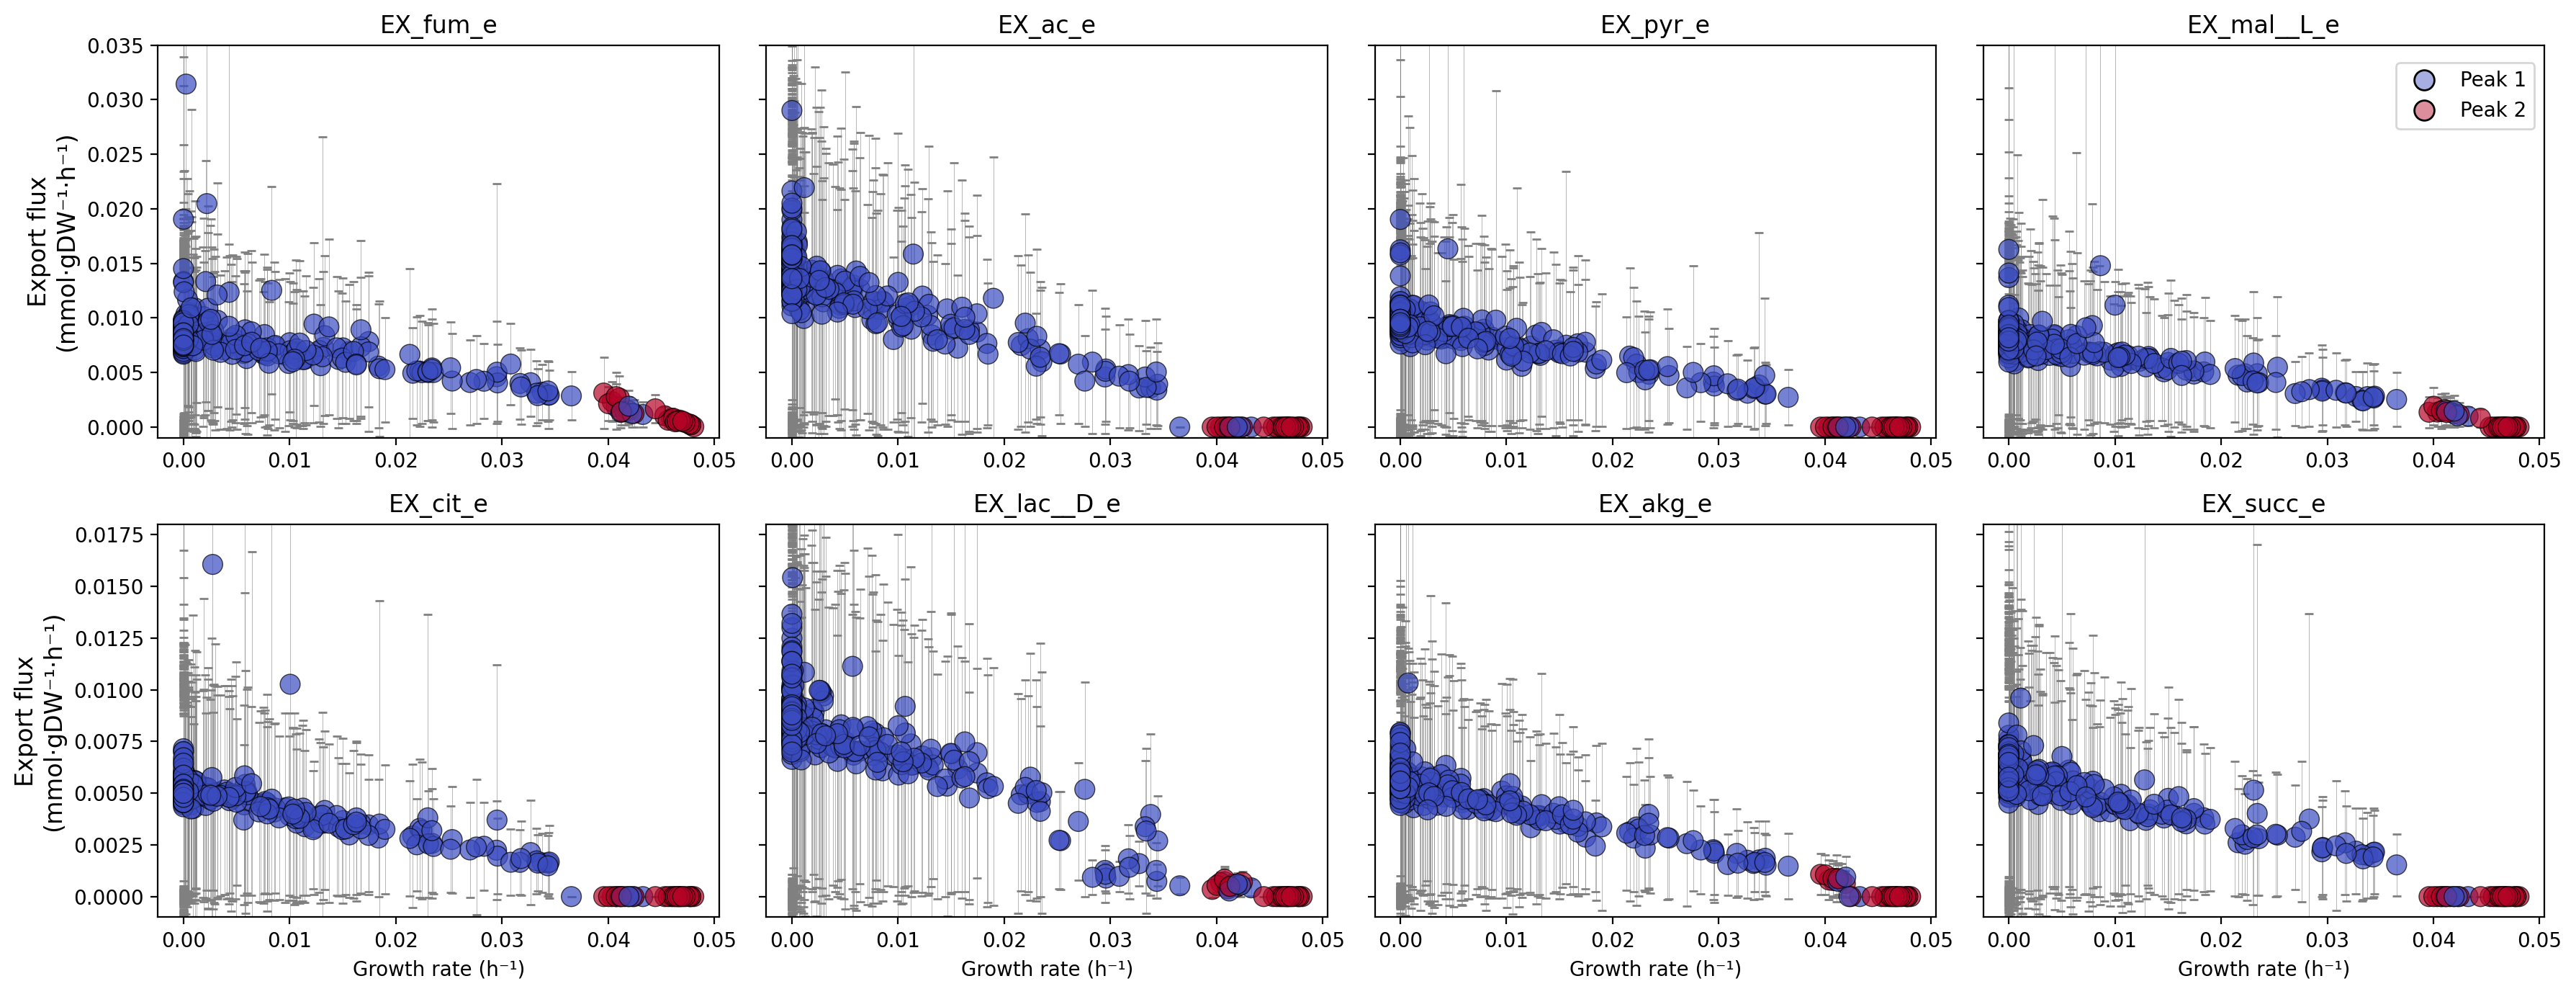

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

means = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat',
    sep='\t'
)


indexes = []
files = os.listdir('results_new/genome_scale_samples_no_exchange_PEAKS/')
for f in files: 
    if 'cell' in f: 
        index = int(f.split('cell')[-1].split('.dat')[0])
        indexes.append(index)

indexes = sorted(indexes)

stds = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat',
    sep='\t'
)

clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
clusters = clusters.loc[indexes]

# -------------------------
# CLUSTER -> COLOR MAPPING
# -------------------------
# Assumption: clusters has the same rows/order as means & stds,
# and the LAST column holds the cluster/peak label.
# If that's wrong, set cluster_col explicitly, e.g. cluster_col = 'cluster'
cluster_col = 'cluster'
cluster_labels = clusters[cluster_col]

unique_clusters = sorted(cluster_labels.unique(), key=lambda v: str(v))
if len(unique_clusters) != 2:
    raise ValueError(
        f"Esperaba 2 clusters (Peak 1/Peak 2), encontré {len(unique_clusters)}: {unique_clusters}. "
        "Revisa cluster_col."
    )

cmap = plt.cm.coolwarm
color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
cluster_color_map = {unique_clusters[0]: color_peak1, unique_clusters[1]: color_peak2}
point_colors = cluster_labels.map(cluster_color_map).to_numpy()

x_vals = means['BIOMASS_Ec_SynAuto']

# -------------------------
# ORDER ACIDS BY MAX VALUE
# -------------------------
acids = list(acids_set)

acids_sorted = sorted(
    acids,
    key=lambda a: np.nanmax(means[a]),
    reverse=True
)

# -------------------------
# SPLIT INTO 2 ROWS
# -------------------------
mid = (len(acids_sorted) + 1) // 2
row1 = acids_sorted[:mid]
row2 = acids_sorted[mid:]

fig, axes = plt.subplots(
    2,
    max(len(row1), len(row2)),
    figsize=(4.5 * max(len(row1), len(row2)), 7),
    sharey='row',
    dpi=200
)
axes = np.array(axes)

def plot_row(row, axes_row, y_min, y_max):
    for i, acid in enumerate(row):
        y_vals = means[acid]
        y_err  = stds[acid]
        ax = axes_row[i]

        # error bars only (grey, no markers)
        ax.errorbar(
            x_vals, y_vals, yerr=y_err,
            fmt='none',
            elinewidth=0.2,
            ecolor='grey',
            capsize=2,
            zorder=1,
        )

        # markers colored by cluster
        ax.scatter(
            x_vals, y_vals,
            c=point_colors,
            s=100,                  # ~ markersize=10 equivalent
            edgecolor='black',
            linewidth=0.5,
            alpha=0.7,
            zorder=2,
        )

        ax.set_title(acid)
        ax.set_ylim(y_min, y_max)
        ax.grid(False)

        if i == 0:
            ax.set_ylabel("Export flux\n(mmol·gDW⁻¹·h⁻¹)", fontsize=12)

# -------------------------
# ROW 1
# -------------------------
plot_row(row1, axes[0], y_min=-0.001, y_max=0.035)

# -------------------------
# ROW 2
# -------------------------
plot_row(row2, axes[1], y_min=-0.001, y_max=0.018)

for i, acid in enumerate(row2):
    axes[1, i].set_xlabel("Growth rate (h⁻¹)")

# -------------------------
# SHARED LEGEND
# -------------------------
from matplotlib.lines import Line2D
legend_handles = [
    Line2D([0], [0], marker='o', linestyle='', markerfacecolor=color_peak1,
           markeredgecolor='black', markersize=10, label=f"Peak 1"),
    Line2D([0], [0], marker='o', linestyle='', markerfacecolor=color_peak2,
           markeredgecolor='black', markersize=10, label=f"Peak 2"),
]
fig.legend(handles=legend_handles, loc=(0.93,0.87), frameon=True)
plt.tight_layout()

plt.savefig('secretion.png', dpi=200, format='png',bbox_inches='tight' )
plt.show()

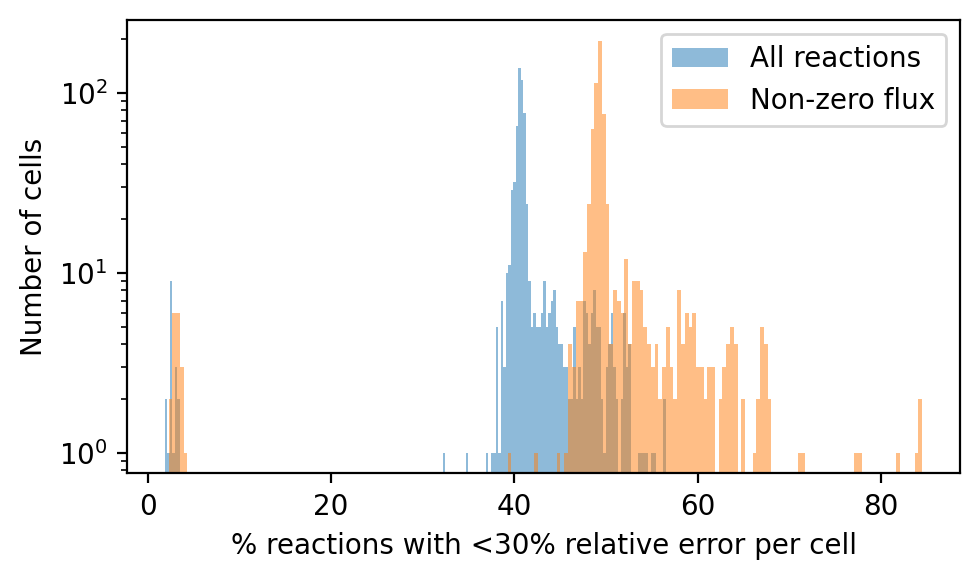

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

means = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange/std_sampling_exchange_stds.dat',
    sep='\t'
)

reactions = [c for c in means.columns if c != means.columns[0]]

means_r = means[reactions]
stds_r  = stds[reactions]

# -------------------------
# relative error
# -------------------------
rel_err = stds_r / np.abs(means_r)
rel_err = rel_err.replace([np.inf, -np.inf], np.nan)

threshold = 0.3

# =========================================================
# ALL REACTIONS
# =========================================================
good_all = (rel_err < threshold).sum(axis=1)
percent_all = 100 * good_all / rel_err.shape[1]

# =========================================================
# NON-ZERO FLUX ONLY (per cell)
# =========================================================
mask_nonzero = np.abs(means_r) > 1e-12
rel_err_nonzero = rel_err.where(mask_nonzero)

good_nonzero = (rel_err_nonzero < threshold).sum(axis=1)
n_nonzero = mask_nonzero.sum(axis=1)

percent_nonzero = 100 * good_nonzero / n_nonzero
percent_nonzero = percent_nonzero.replace([np.inf, -np.inf], np.nan)

# =========================================================
# SINGLE HISTOGRAM (OVERLAID)
# =========================================================
plt.figure(figsize=(5,3), dpi=200)

plt.hist(percent_all, bins=200, alpha=0.5, label="All reactions", log=True)
plt.hist(percent_nonzero.dropna(), bins=200, alpha=0.5, label="Non-zero flux",  log=True)

plt.xlabel("% reactions with <30% relative error per cell")
plt.ylabel("Number of cells")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()


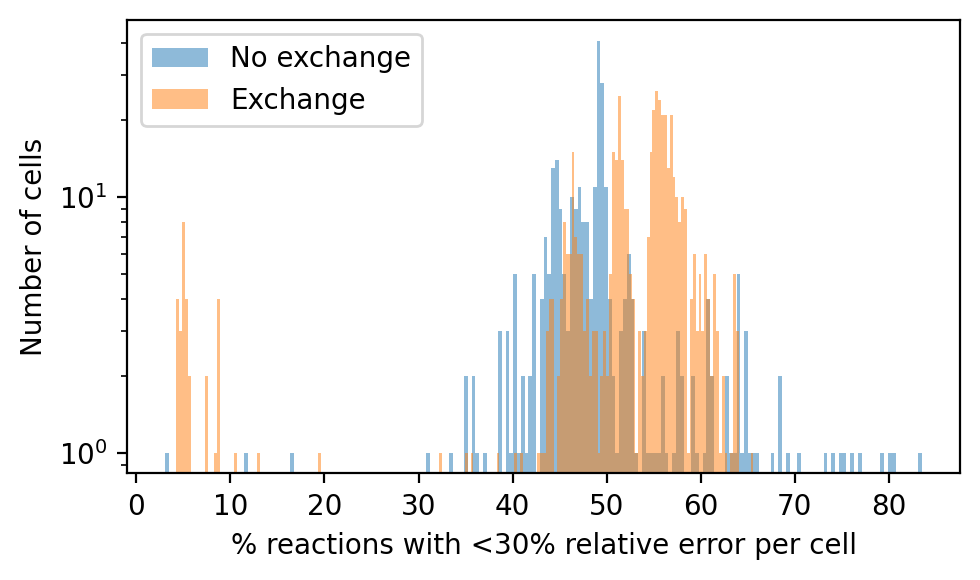

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

means = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat',
    sep='\t'
)

means2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat',
    sep='\t'
)

reactions = [c for c in means.columns if c != means.columns[0]]

means_r = means[reactions]
stds_r  = stds[reactions]

# -------------------------
# relative error
# -------------------------
rel_err = stds_r / np.abs(means_r)
rel_err = rel_err.replace([np.inf, -np.inf], np.nan)

threshold = 0.3

# =========================================================
# ALL REACTIONS
# =========================================================
good_all = (rel_err < threshold).sum(axis=1)
percent_all = 100 * good_all / rel_err.shape[1]

# =========================================================
# NON-ZERO FLUX ONLY (per cell)
# =========================================================
mask_nonzero = np.abs(means_r) > 1e-12
rel_err_nonzero = rel_err.where(mask_nonzero)

good_nonzero = (rel_err_nonzero < threshold).sum(axis=1)
n_nonzero = mask_nonzero.sum(axis=1)

percent_nonzero = 100 * good_nonzero / n_nonzero
percent_nonzero = percent_nonzero.replace([np.inf, -np.inf], np.nan)



reactions = [c for c in means2.columns if c != means2.columns[0]]

means_r = means2[reactions]
stds_r  = stds2[reactions]

# -------------------------
# relative error
# -------------------------
rel_err = stds_r / np.abs(means_r)
rel_err = rel_err.replace([np.inf, -np.inf], np.nan)

threshold = 0.3

# =========================================================
# ALL REACTIONS
# =========================================================
good_all2 = (rel_err < threshold).sum(axis=1)
percent_all2 = 100 * good_all / rel_err.shape[1]

# =========================================================
# NON-ZERO FLUX ONLY (per cell)
# =========================================================
mask_nonzero2 = np.abs(means_r) > 1e-12
rel_err_nonzero2 = rel_err.where(mask_nonzero2)

good_nonzero2 = (rel_err_nonzero2 < threshold).sum(axis=1)
n_nonzero2 = mask_nonzero2.sum(axis=1)

percent_nonzero2 = 100 * good_nonzero2 / n_nonzero2
percent_nonzero2 = percent_nonzero2.replace([np.inf, -np.inf], np.nan)




# =========================================================
# SINGLE HISTOGRAM (OVERLAID)
# =========================================================
plt.figure(figsize=(5,3), dpi=200)

plt.hist(percent_nonzero.dropna(), bins=200, alpha=0.5, label="No exchange", log=True)
plt.hist(percent_nonzero2.dropna(), bins=200, alpha=0.5, label="Exchange",  log=True)

plt.xlabel("% reactions with <30% relative error per cell")
plt.ylabel("Number of cells")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()


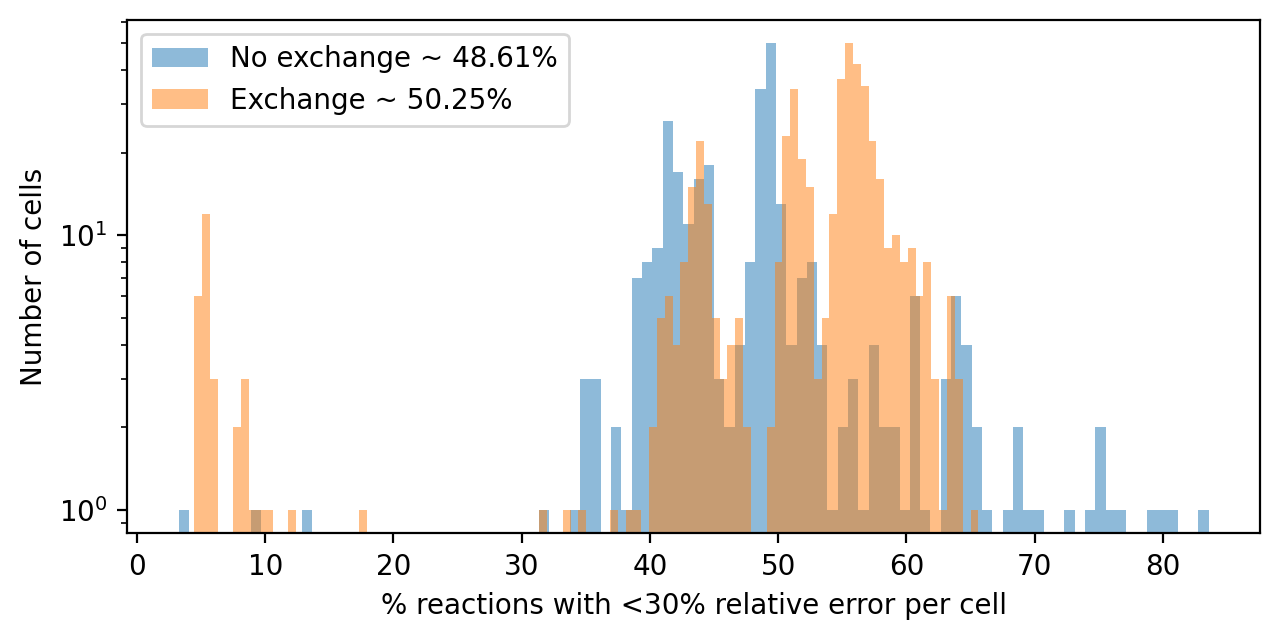


=== CONVERGENCE (NON-ZERO REACTIONS ONLY) ===
No exchange - mean: 48.61328028004425
Exchange    - mean: 50.25160124709373


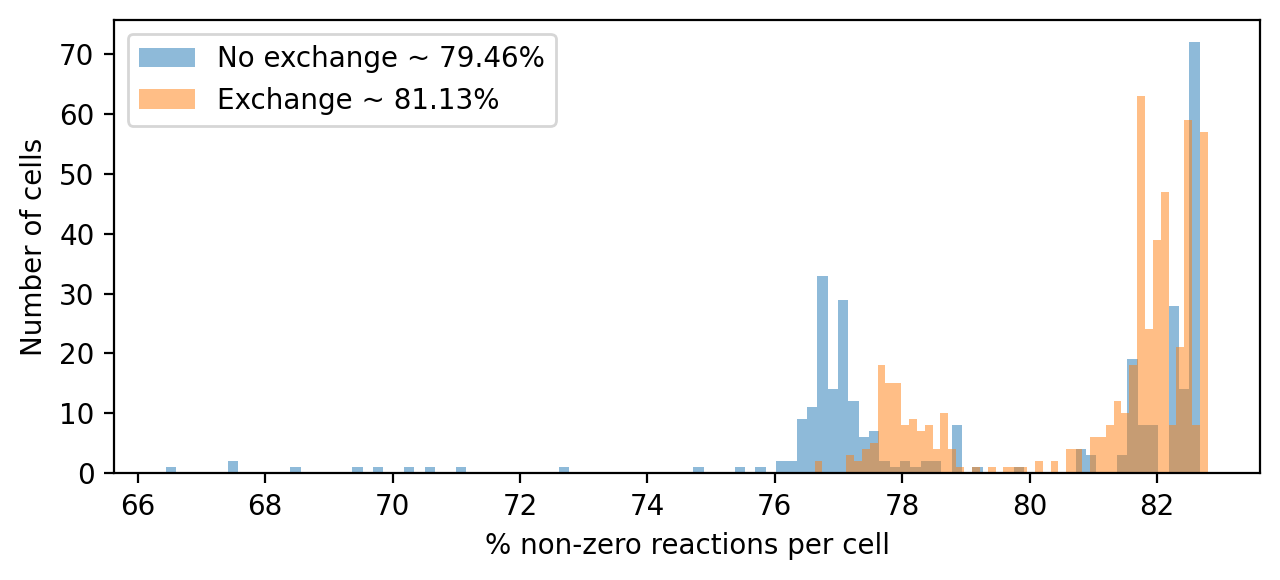

=== NO EXCHANGE ===
Mean % non-zero reactions: 79.4559230088927
Mean % zero reactions: 20.544076991107303

=== EXCHANGE ===
Mean % non-zero reactions: 81.12705554822423
Mean % zero reactions: 18.872944451775766


In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# LOAD DATA
# =========================================================
means = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat',
    sep='\t'
)

means2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat',
    sep='\t'
)

threshold = 0.3


# =========================================================
# FUNCTION TO PROCESS DATASET
# =========================================================
def analyze_dataset(means_df, stds_df):
    reactions = [c for c in means_df.columns if c != means_df.columns[0]]

    means_r = means_df[reactions]
    stds_r  = stds_df[reactions]

    # -------------------------
    # relative error
    # -------------------------
    rel_err = stds_r / np.abs(means_r)
    rel_err = rel_err.replace([np.inf, -np.inf], np.nan)

    # =====================================================
    # ALL REACTIONS
    # =====================================================
    good_all = (rel_err < threshold).sum(axis=1)
    percent_all = 100 * good_all / rel_err.shape[1]

    # =====================================================
    # NON-ZERO FLUX ONLY
    # =====================================================
    mask_nonzero = np.abs(means_r) > 1e-9
    rel_err_nonzero = rel_err.where(mask_nonzero)

    good_nonzero = (rel_err_nonzero < threshold).sum(axis=1)
    n_nonzero = mask_nonzero.sum(axis=1)

    percent_nonzero = 100 * good_nonzero / n_nonzero
    percent_nonzero = percent_nonzero.replace([np.inf, -np.inf], np.nan)

    # =====================================================
    # ZERO vs NON-ZERO REACTIONS
    # =====================================================
    n_total = means_r.shape[1]
    n_zero = n_total - n_nonzero

    percent_nonzero_rxn = 100 * n_nonzero / n_total
    percent_zero_rxn = 100 * n_zero / n_total

    return {
        "percent_all": percent_all,
        "percent_nonzero": percent_nonzero,
        "percent_nonzero_rxn": percent_nonzero_rxn,
        "percent_zero_rxn": percent_zero_rxn
    }


# =========================================================
# RUN ANALYSIS
# =========================================================
res1 = analyze_dataset(means, stds)
res2 = analyze_dataset(means2, stds2)


# =========================================================
# HISTOGRAM: CONVERGENCE (NON-ZERO ONLY)
# =========================================================
plt.figure(figsize=(6.5,3.3), dpi=200)

plt.hist(res1["percent_nonzero"].dropna(), bins=100, alpha=0.5,
         label="No exchange ~ "+str(round(np.mean(res1["percent_nonzero"].dropna()),2))+'%', log=True)

plt.hist(res2["percent_nonzero"].dropna(), bins=100, alpha=0.5,
         label="Exchange ~ "+str(round(np.mean(res2["percent_nonzero"].dropna()),2))+'%', log=True)

plt.xlabel("% reactions with <30% relative error per cell")
plt.ylabel("Number of cells")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.savefig('resolved_network.png', format='png', dpi=200, bbox_inches ='tight')

plt.show()

# =========================================================
# PRINT AVERAGES FOR FIRST HISTOGRAM
# (% reactions with <30% relative error, non-zero only)
# =========================================================
print("\n=== CONVERGENCE (NON-ZERO REACTIONS ONLY) ===")
print("No exchange - mean:", res1["percent_nonzero"].mean())
print("Exchange    - mean:", res2["percent_nonzero"].mean())


# =========================================================
# HISTOGRAM: NON-ZERO FRACTION
# =========================================================
plt.figure(figsize=(6.5,3), dpi=200)

plt.hist(res1["percent_nonzero_rxn"], bins=100, alpha=0.5,
         label="No exchange ~ "+str(round(np.mean(res1["percent_nonzero_rxn"].dropna()),2))+'%')

plt.hist(res2["percent_nonzero_rxn"], bins=50, alpha=0.5,
         label="Exchange ~ "+str(round(np.mean(res2["percent_nonzero_rxn"].dropna()),2))+'%')

plt.xlabel("% non-zero reactions per cell")
plt.ylabel("Number of cells")
plt.legend()
plt.tight_layout()
plt.savefig('non_zero.png', format='png', dpi=200, bbox_inches ='tight')

plt.show()


# =========================================================
# OPTIONAL: PRINT SUMMARY STATS
# =========================================================
print("=== NO EXCHANGE ===")
print("Mean % non-zero reactions:", res1["percent_nonzero_rxn"].mean())
print("Mean % zero reactions:", res1["percent_zero_rxn"].mean())

print("\n=== EXCHANGE ===")
print("Mean % non-zero reactions:", res2["percent_nonzero_rxn"].mean())
print("Mean % zero reactions:", res2["percent_zero_rxn"].mean())

/tmp/ipykernel_34116/1525736941.py:143: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


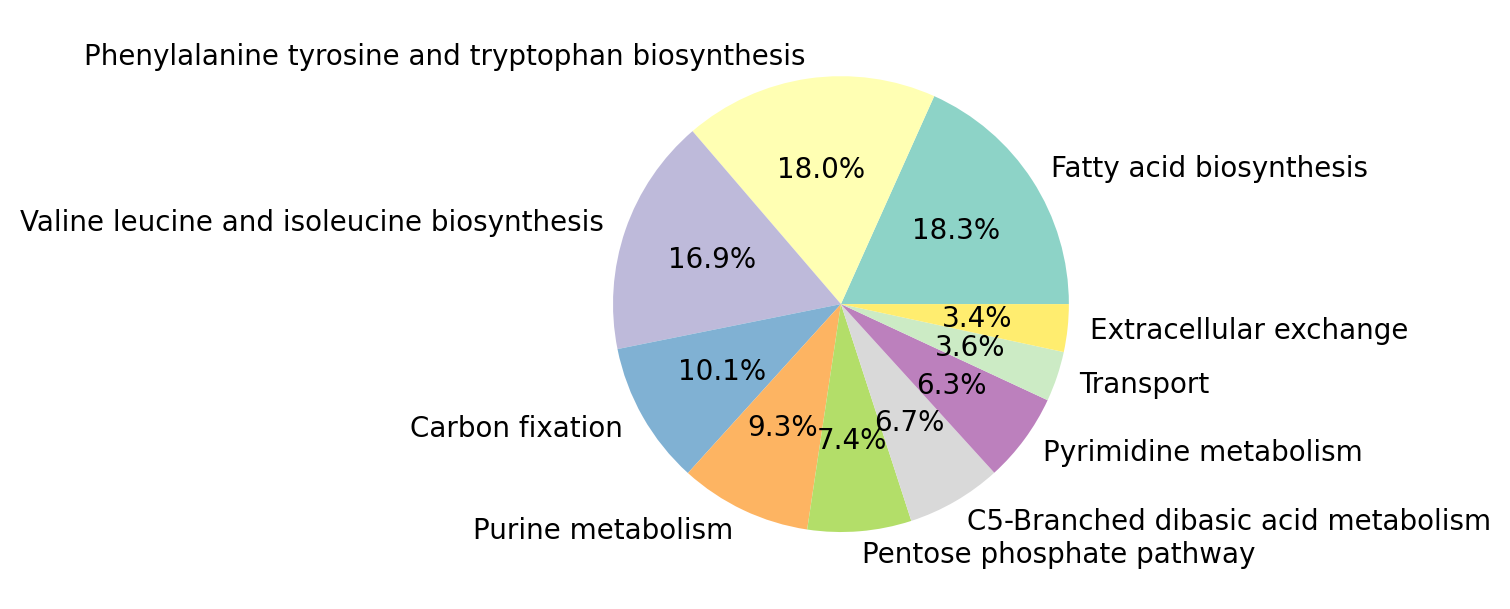

/tmp/ipykernel_34116/1525736941.py:153: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


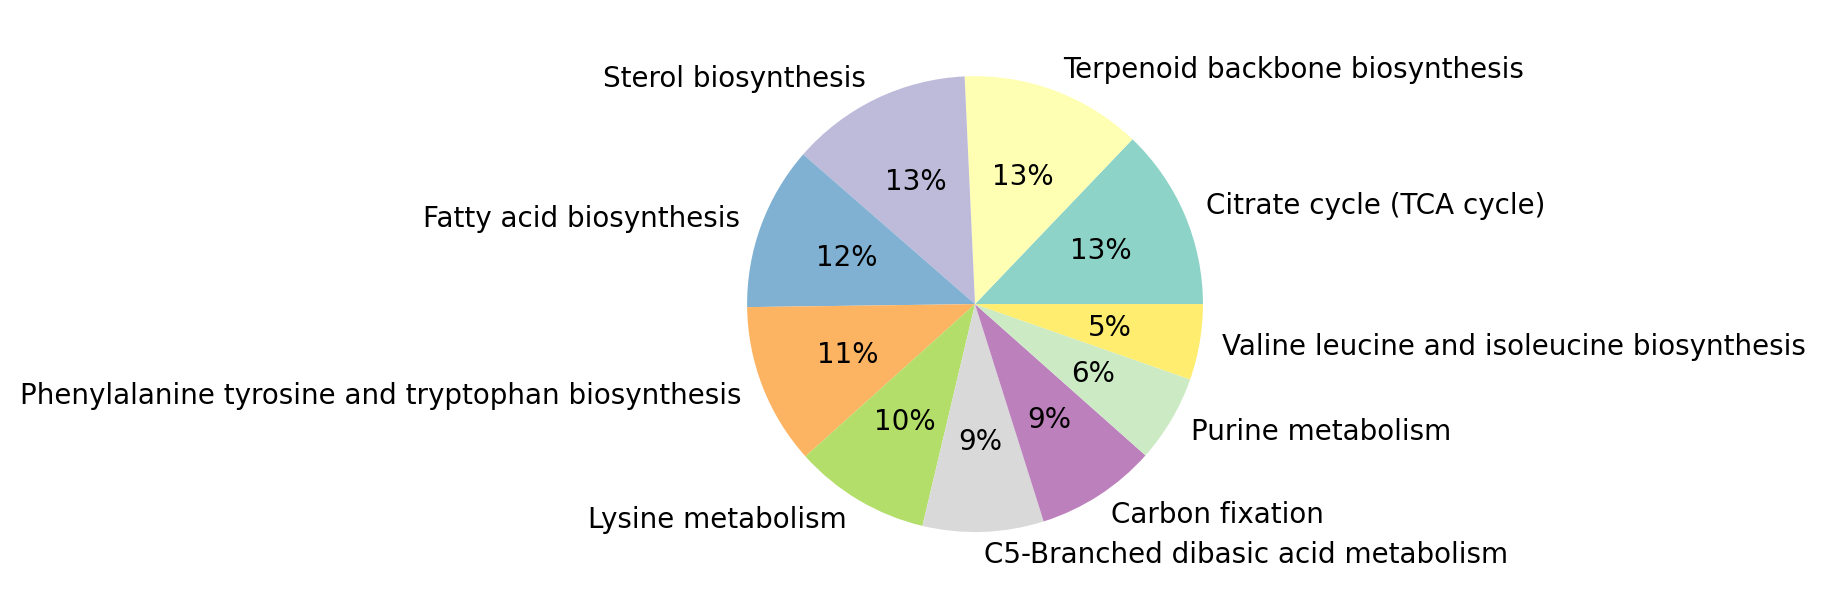

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import cobra
#model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# =========================================================
# LOAD DATA
# =========================================================
means = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds = pd.read_csv(
    'results_new/genome_scale_samples_no_exchange_PEAKS/std_sampling_exchange_stds.dat',
    sep='\t'
)

means2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_averages.dat',
    sep='\t'
)

stds2 = pd.read_csv(
    'results_new/genome_scale_samples_PEAKS_RuBisCO_ox/std_sampling_exchange_stds.dat',
    sep='\t'
)

threshold = 0.3

# =========================================================
# REACTION → SUBSYSTEM MAP
# =========================================================
rxn_to_subsystem = {r.id: r.subsystem for r in model.reactions}


# =========================================================
# FUNCTION (NON-ZERO FILTERED)
# =========================================================
def compute_subsystem_ratios_nonzero(means_df, stds_df):

    reactions = [c for c in means_df.columns if c != means_df.columns[0]]

    means_r = means_df[reactions]
    stds_r  = stds_df[reactions]

    # -------------------------
    # relative error
    # -------------------------
    rel_err = stds_r / np.abs(means_r)
    rel_err = rel_err.replace([np.inf, -np.inf], np.nan)

    # -------------------------
    # NON-ZERO MASK
    # -------------------------
    mask_nonzero = np.abs(means_r) > 1e-2

    # only evaluate where reaction is active
    rel_err_active = rel_err.where(mask_nonzero)

    # -------------------------
    # GOOD CONVERGENCE (only active)
    # -------------------------
    good_mask = rel_err_active < threshold

    # fraction of ACTIVE cells where reaction is good
    good_fraction = good_mask.sum(axis=0) / mask_nonzero.sum(axis=0)

    # avoid division by zero
    good_fraction = good_fraction.replace([np.inf, -np.inf], np.nan)

    good_rxn = good_fraction > 0.5

    # -------------------------
    # aggregate per subsystem
    # -------------------------
    subsystem_total = defaultdict(int)
    subsystem_good  = defaultdict(int)

    for rxn in reactions:
        subsystem = rxn_to_subsystem.get(rxn, "Unknown")

        # only count reactions that are EVER active
        if mask_nonzero[rxn].sum() == 0:
            continue

        subsystem_total[subsystem] += 1

        if good_rxn.get(rxn, False):
            subsystem_good[subsystem] += 1

    # -------------------------
    # normalized ratio
    # -------------------------
    subsystem_ratio = {
        s: subsystem_good[s] / subsystem_total[s]
        for s in subsystem_total if subsystem_total[s] > 0
    }

    return subsystem_ratio, subsystem_total


# =========================================================
# COMPUTE
# =========================================================
ratio1, total1 = compute_subsystem_ratios_nonzero(means, stds)
ratio2, total2 = compute_subsystem_ratios_nonzero(means2, stds2)


# =========================================================
# TOP N ONLY
# =========================================================
def get_top_subsystems(ratio_dict, total_dict, top_n=10, min_size=2):

    filtered = {k: v for k, v in ratio_dict.items() if total_dict[k] > min_size}

    sorted_items = sorted(filtered.items(), key=lambda x: x[1], reverse=True)

    top_items = sorted_items[:top_n]

    labels = [k for k, _ in top_items]
    values = [v for _, v in top_items]

    return labels, values


labels1, values1 = get_top_subsystems(ratio1, total1)
labels2, values2 = get_top_subsystems(ratio2, total2)


# =========================================================
# PLOT — NO EXCHANGE
# =========================================================
colors1 = plt.cm.Set3(np.linspace(0, 1, len(values1)))   # soft pastel
plt.figure(figsize=(3.7,3.7), dpi=200)
plt.pie(values1, labels=labels1, autopct='%1.1f%%', colors=colors1)
plt.tight_layout()
plt.savefig('piechart_no_ex.png', format='png', dpi=200, bbox_inches ='tight')
plt.show()


# =========================================================
# PLOT — EXCHANGE
# =========================================================
plt.figure(figsize=(3.7,3.7), dpi=200)
plt.pie(values2, labels=labels2, autopct='%1.f%%', colors=colors1)
plt.tight_layout()
plt.savefig('piechart_ex.png', format='png', dpi=200, bbox_inches ='tight')
plt.show()